Connected to Python 3.13.0

In [ ]:
import os
import sys
import numpy as np
import anndata as ad
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

# Add current directory to path for imports
current_dir = os.path.dirname(os.path.abspath(__file__))
if current_dir not in sys.path:
    sys.path.insert(0, current_dir)

# Import visualization functions
import importlib
import visualization_functions

importlib.reload(visualization_functions)  # Force reload to avoid cache issues

from visualization_functions import (
    plot_violin_stripplot_by_group,
)

In [ ]:
# Set working directory
os.chdir(os.path.dirname(os.path.dirname(os.path.dirname(os.path.abspath(__file__)))))

In [ ]:
# Load the filtered data from 3b_v2
print("📂 Loading filtered data from 3b_v2...")
INPUT_PATH = "data/Anndata/filtered"
INPUT_FILE = "GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_3b_v2.h5ad"

# Load the filtered data
adata_filtered_cells_3b_v2 = ad.read_h5ad(os.path.join(INPUT_PATH, INPUT_FILE))

print(
    f"📊 Loaded dataset: {adata_filtered_cells_3b_v2.n_obs:,} cells × {adata_filtered_cells_3b_v2.n_vars:,} genes"
)
print(f"🔢 Available obs columns: {list(adata_filtered_cells_3b_v2.obs.columns)}")
print(f"🔢 Available var columns: {list(adata_filtered_cells_3b_v2.var.columns)}")

📂 Loading filtered data from 3b_v2...
📊 Loaded dataset: 2,988 cells × 6,248 genes
🔢 Available obs columns: ['barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Extracted_Sequence_rd1', 'Group', 'n_counts', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'group']
🔢 Available var columns: ['gene_id', 'final_gene_name', 'symbol_renamed', 'Gene Type', 'Name', 'Protein accession', 'symbol_old', 'locus_tag_old']



📊 STEP 1: INITIAL DATASET VISUALIZATIONS
🧬 Gene Type distribution:
Gene Type
protein-coding    6099
tRNA                65
pseudogene          63
rRNA                16
other                3
RNase_P_RNA          1
ncRNA                1
Name: count, dtype: int64
🧮 Recalculating QC metrics...

📊 1.1 Generating violin + stripplot for n_genes...


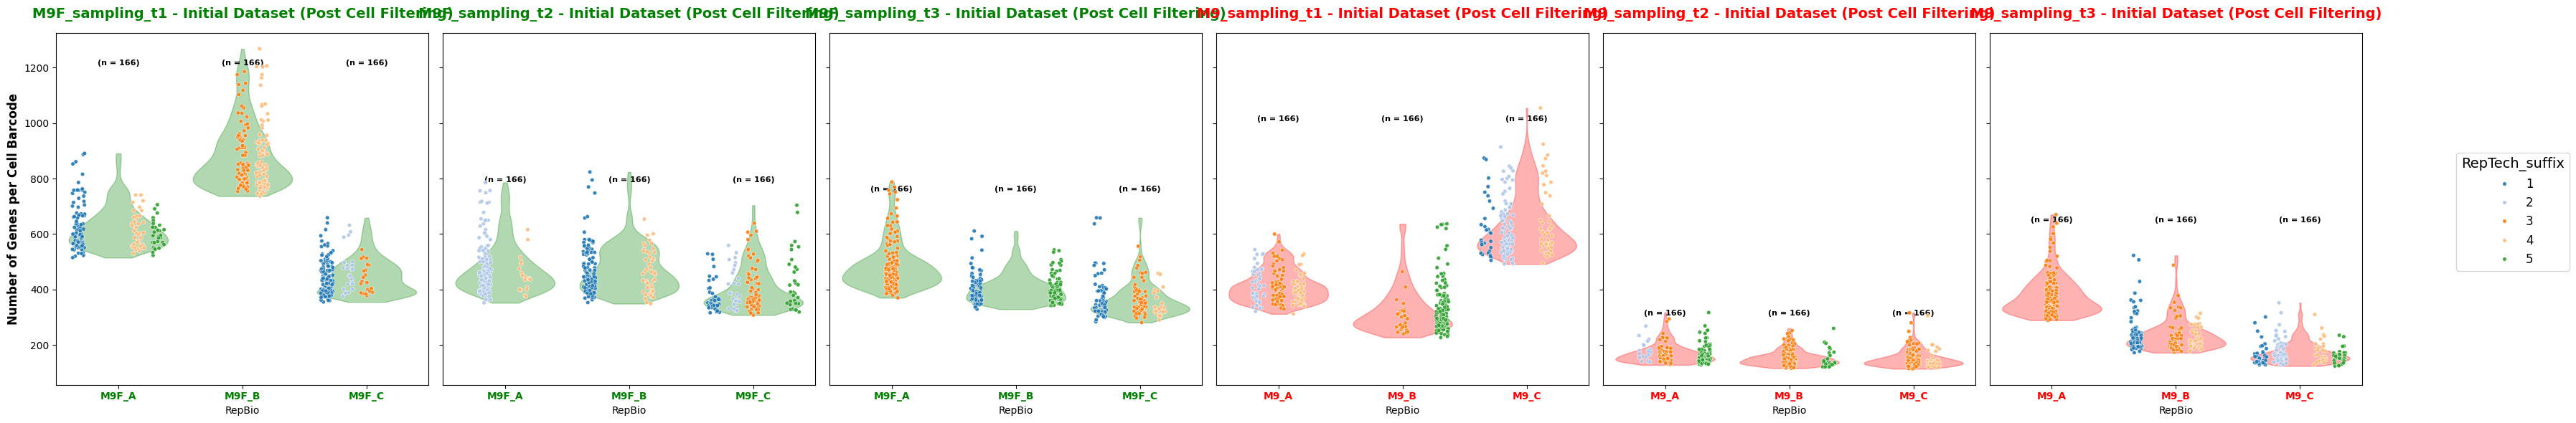


📊 1.2 Generating violin + stripplot for total_counts...


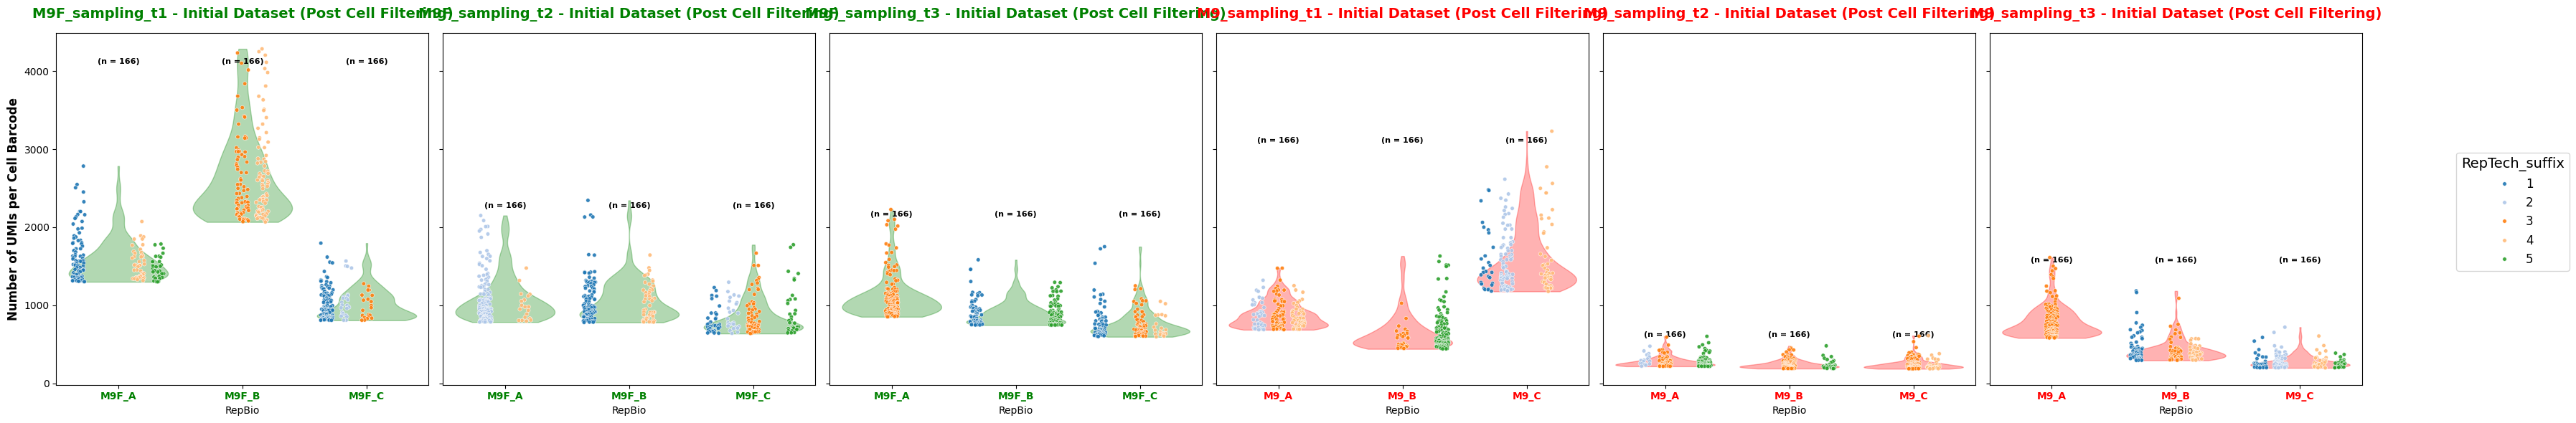

In [ ]:
# STEP 1: Initial dataset visualizations
print("\n" + "=" * 80)
print("📊 STEP 1: INITIAL DATASET VISUALIZATIONS")
print("=" * 80)

# Display gene type distribution
print("🧬 Gene Type distribution:")
if "Gene Type" in adata_filtered_cells_3b_v2.var.columns:
    print(adata_filtered_cells_3b_v2.var["Gene Type"].value_counts())
else:
    print("⚠️  'Gene Type' column not found in var")

# Recalculate QC metrics to ensure we have n_genes and total_counts
print("🧮 Recalculating QC metrics...")
sc.pp.calculate_qc_metrics(adata_filtered_cells_3b_v2, inplace=True, log1p=True)

# Violin + stripplot for n_genes
print("\n📊 1.1 Generating violin + stripplot for n_genes...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_cells_3b_v2,
    y_column="n_genes",
    y_label="Number of Genes per Cell Barcode",
    title_suffix=" - Initial Dataset (Post Cell Filtering)",
    figsize_per_plot=6,
)

# Violin + stripplot for total_counts (UMIs)
print("\n📊 1.2 Generating violin + stripplot for total_counts...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_cells_3b_v2,
    y_column="total_counts",
    y_label="Number of UMIs per Cell Barcode",
    title_suffix=" - Initial Dataset (Post Cell Filtering)",
    figsize_per_plot=6,
)


📊 STEP 2: PROTEIN-CODING GENE FILTERING
📊 Before protein-coding filtering: 6,248 genes
📊 After protein-coding filtering: 6,099 genes
🗑️ Removed genes: 149

🧬 Remaining gene types:
Gene Type
protein-coding    6099
Name: count, dtype: int64
🧮 Recalculating QC metrics after protein-coding filtering...

📊 2.1 Generating violin + stripplot for n_genes...


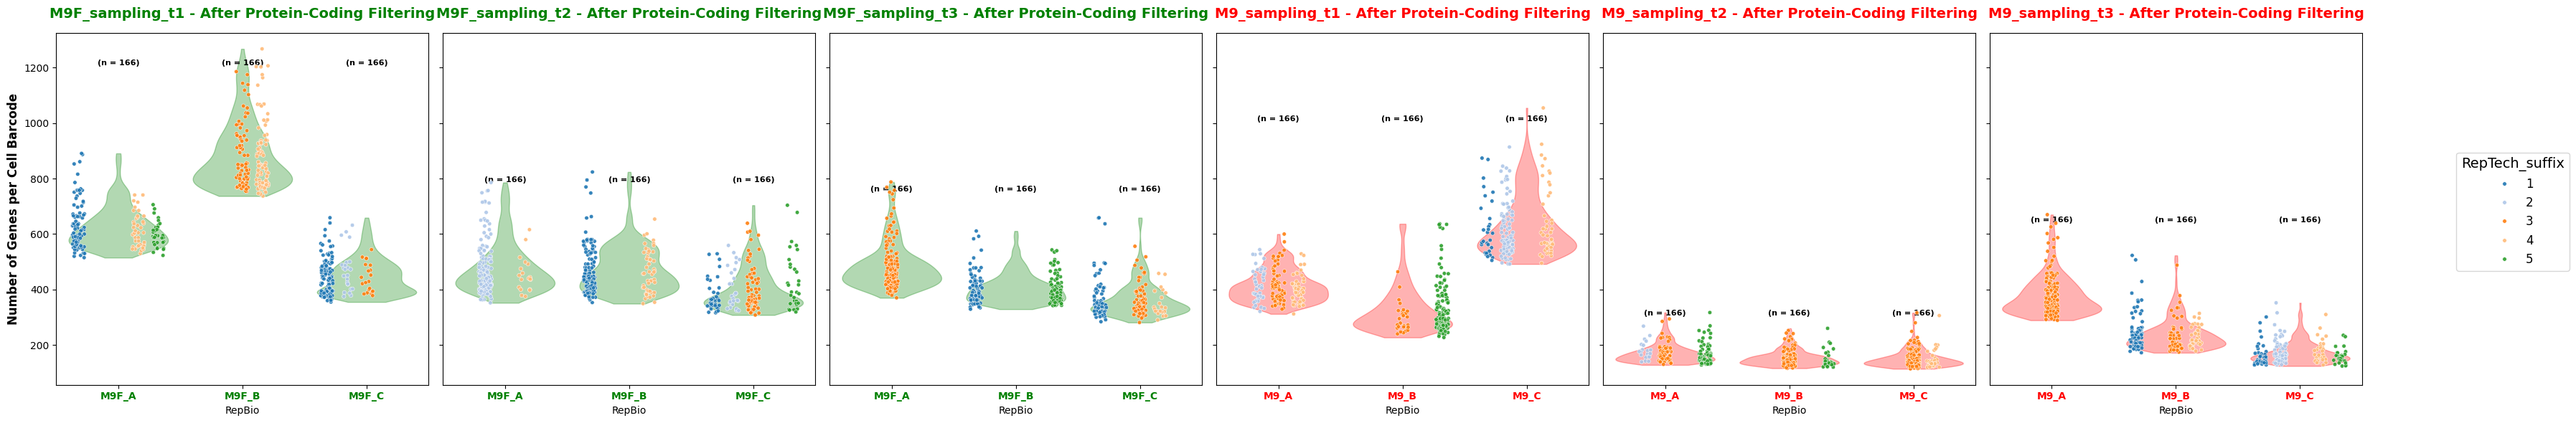


📊 2.2 Generating violin + stripplot for total_counts...


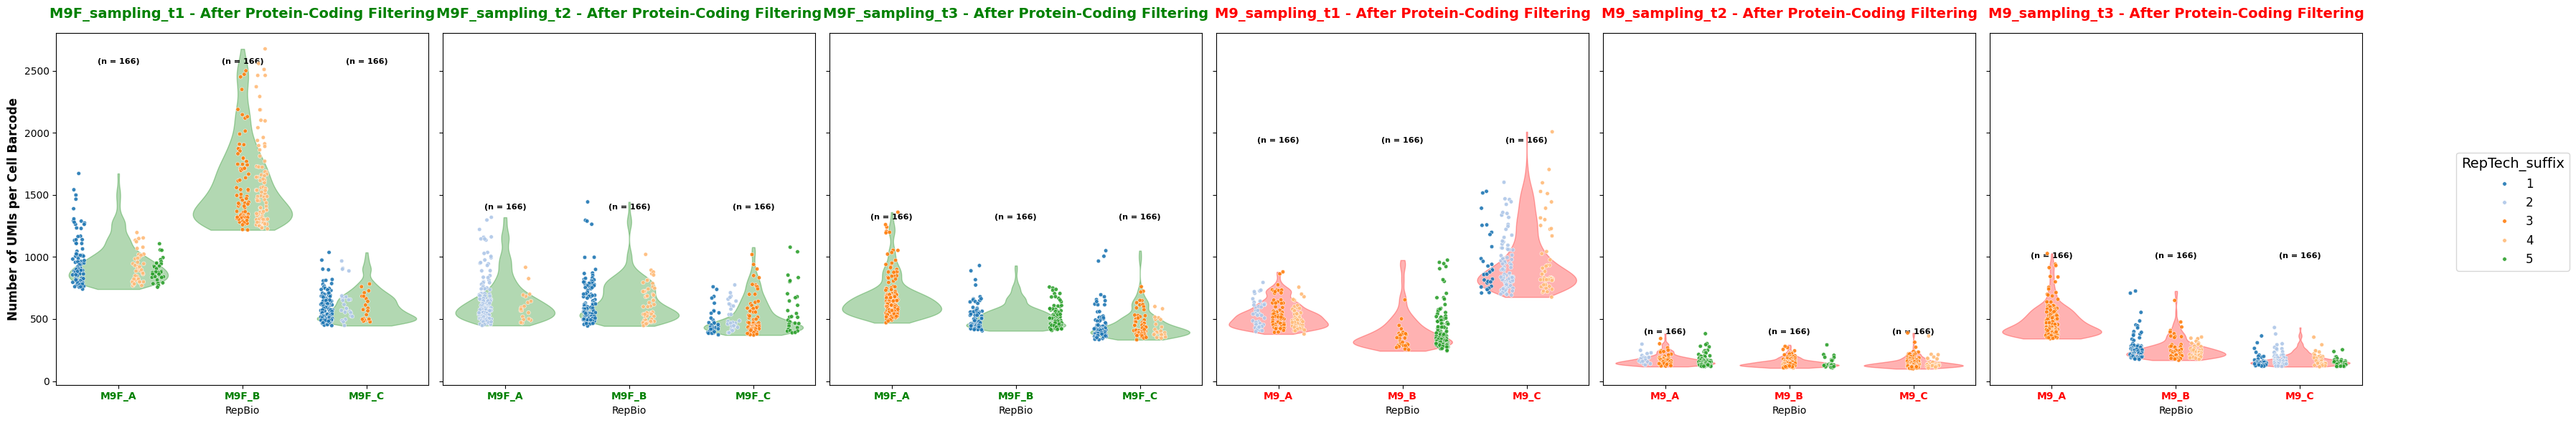

In [ ]:
# STEP 2: Protein-coding gene filtering
print("\n" + "=" * 80)
print("📊 STEP 2: PROTEIN-CODING GENE FILTERING")
print("=" * 80)

print(
    f"📊 Before protein-coding filtering: {adata_filtered_cells_3b_v2.n_vars:,} genes"
)

# Filter for protein-coding genes only
if "Gene Type" in adata_filtered_cells_3b_v2.var.columns:
    protein_coding_mask = (
        adata_filtered_cells_3b_v2.var["Gene Type"] == "protein-coding"
    )
    adata_filtered_protein_coding = adata_filtered_cells_3b_v2[
        :, protein_coding_mask
    ].copy()

    print(
        f"📊 After protein-coding filtering: {adata_filtered_protein_coding.n_vars:,} genes"
    )
    print(
        f"🗑️ Removed genes: {adata_filtered_cells_3b_v2.n_vars - adata_filtered_protein_coding.n_vars:,}"
    )

    # Show remaining gene types
    print("\n🧬 Remaining gene types:")
    print(adata_filtered_protein_coding.var["Gene Type"].value_counts())
else:
    print("⚠️  'Gene Type' column not found, skipping protein-coding filtering")
    adata_filtered_protein_coding = adata_filtered_cells_3b_v2.copy()

# Remove n_counts column if it exists to avoid conflicts
if "n_counts" in adata_filtered_protein_coding.obs.columns:
    adata_filtered_protein_coding.obs.drop(columns=["n_counts"], inplace=True)

# Recalculate QC metrics after gene filtering
print("🧮 Recalculating QC metrics after protein-coding filtering...")
sc.pp.calculate_qc_metrics(adata_filtered_protein_coding, inplace=True, log1p=True)

# Visualizations after protein-coding filtering
print("\n📊 2.1 Generating violin + stripplot for n_genes...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_protein_coding,
    y_column="n_genes",
    y_label="Number of Genes per Cell Barcode",
    title_suffix=" - After Protein-Coding Filtering",
    figsize_per_plot=6,
)

print("\n📊 2.2 Generating violin + stripplot for total_counts...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_protein_coding,
    y_column="total_counts",
    y_label="Number of UMIs per Cell Barcode",
    title_suffix=" - After Protein-Coding Filtering",
    figsize_per_plot=6,
)


📊 STEP 3: MINIMUM CELLS PER GENE FILTERING
📊 Before min cells filtering: 6,099 genes
📊 After min cells filtering: 5,500 genes
🗑️ Removed genes: 599
🧮 Recalculating QC metrics after min cells filtering...

📊 3.1 Generating violin + stripplot for n_genes...


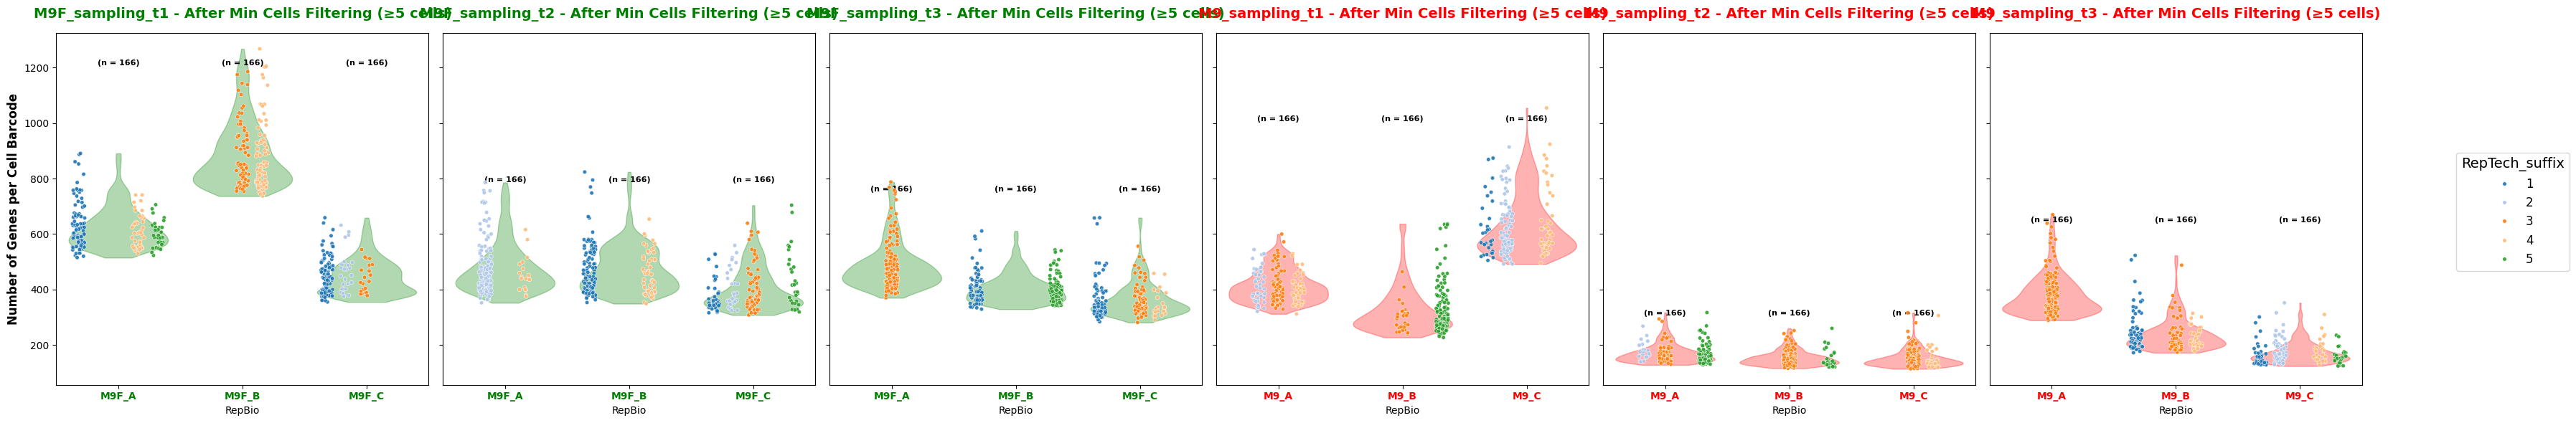


📊 3.2 Generating violin + stripplot for total_counts...


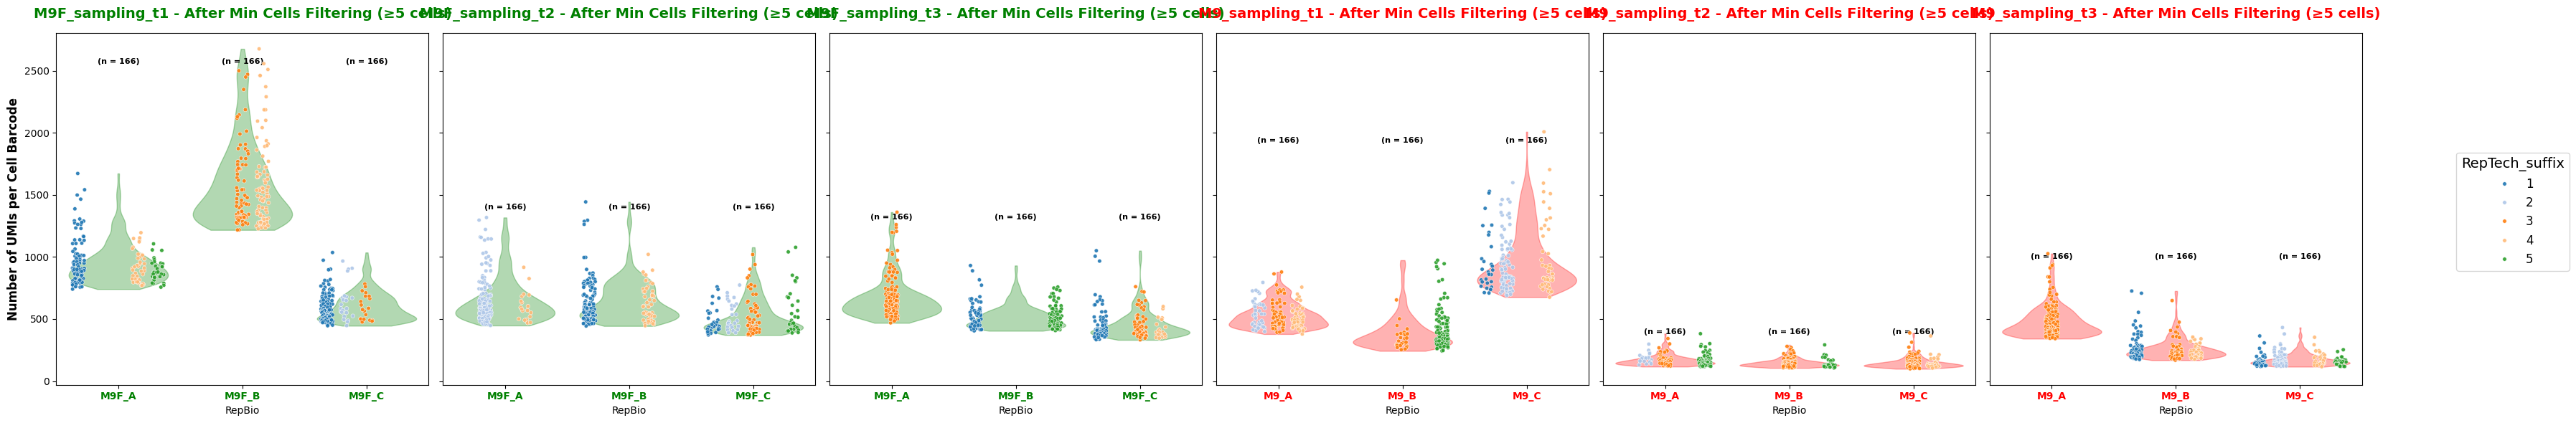

In [ ]:
# STEP 3: Minimum cells per gene filtering
print("\n" + "=" * 80)
print("📊 STEP 3: MINIMUM CELLS PER GENE FILTERING")
print("=" * 80)

MIN_CELLS_PER_GENE = 5

print(f"📊 Before min cells filtering: {adata_filtered_protein_coding.n_vars:,} genes")

# Filter genes expressed in less than MIN_CELLS_PER_GENE cells
adata_filtered_min_cells = adata_filtered_protein_coding.copy()
sc.pp.filter_genes(adata_filtered_min_cells, min_cells=MIN_CELLS_PER_GENE)

print(f"📊 After min cells filtering: {adata_filtered_min_cells.n_vars:,} genes")
print(
    f"🗑️ Removed genes: {adata_filtered_protein_coding.n_vars - adata_filtered_min_cells.n_vars:,}"
)

# Recalculate QC metrics after min cells filtering
print("🧮 Recalculating QC metrics after min cells filtering...")
sc.pp.calculate_qc_metrics(adata_filtered_min_cells, inplace=True, log1p=True)

# Visualizations after min cells filtering
print("\n📊 3.1 Generating violin + stripplot for n_genes...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_min_cells,
    y_column="n_genes",
    y_label="Number of Genes per Cell Barcode",
    title_suffix=" - After Min Cells Filtering (≥5 cells)",
    figsize_per_plot=6,
)

print("\n📊 3.2 Generating violin + stripplot for total_counts...")
plot_violin_stripplot_by_group(
    adata=adata_filtered_min_cells,
    y_column="total_counts",
    y_label="Number of UMIs per Cell Barcode",
    title_suffix=" - After Min Cells Filtering (≥5 cells)",
    figsize_per_plot=6,
)

In [ ]:
def mark_and_filter_genes_by_group_annotated(
    adata,
    groupby: str,
    min_pct_cells: float = 0.05,
    annotate_only: bool = True,
    filter_mode: str = None,  # "union", "intersection", or None
    verbose: bool = True,
):
    """
    Annotate (and optionally filter) genes expressed in ≥ `min_pct_cells` of cells
    for groups defined by `groupby`. Adds two annotation columns to `adata.var`:

    - gene_pass_union_<groupby>_<xxpct>
    - gene_pass_intersection_<groupby>_<xxpct>

    Parameters:
    -----------
    adata : AnnData
        AnnData object to annotate.
    groupby : str
        Name of the grouping column in `adata.obs`.
    min_pct_cells : float
        Percentage threshold (e.g., 0.05 for 5%).
    annotate_only : bool
        If True, only adds annotation columns.
    filter_mode : str
        "union", "intersection" or None. Activates filtering if not None.
    verbose : bool
        Display logs.

    Returns:
    --------
    Annotated (and optionally filtered) AnnData
    """

    if groupby not in adata.obs.columns:
        raise ValueError(f"🛑 '{groupby}' does not exist in adata.obs.")
    if filter_mode not in [None, "union", "intersection"]:
        raise ValueError("🛑 'filter_mode' must be None, 'union' or 'intersection'.")

    is_expressed = adata.X > 0
    n_genes = adata.n_vars
    unique_groups = adata.obs[groupby].unique()
    pct_label = f"{int(min_pct_cells * 100)}pct"
    var_prefix = f"{groupby}_{pct_label}"

    union_mask = np.zeros(n_genes, dtype=bool)
    intersection_mask = np.ones(n_genes, dtype=bool)

    for group in unique_groups:
        mask = adata.obs[groupby] == group
        subset_expr = is_expressed[mask.to_numpy(), :]
        min_cells = int(min_pct_cells * mask.sum())
        genes_ok = np.asarray((subset_expr.sum(axis=0) >= min_cells)).ravel()

        union_mask |= genes_ok
        intersection_mask &= genes_ok

        if verbose:
            print(f"🔍 {group}: {genes_ok.sum()} genes retained (≥ {min_cells} cells)")

    # Add columns with explicit names
    union_col = f"gene_pass_union_{var_prefix}"
    inter_col = f"gene_pass_intersection_{var_prefix}"

    adata.var[union_col] = union_mask
    adata.var[inter_col] = intersection_mask

    if verbose:
        print(
            f"✅ Union: {union_mask.sum()} genes — Intersection: {intersection_mask.sum()} genes"
        )
        print(f"📝 Columns added: {union_col}, {inter_col}")

    if annotate_only:
        return adata

    if filter_mode == "union":
        return adata[:, union_mask].copy()
    elif filter_mode == "intersection":
        return adata[:, intersection_mask].copy()

In [ ]:
# STEP 4: Gene annotation by group expression
print("\n" + "=" * 80)
print("📊 STEP 4: GENE ANNOTATION BY GROUP EXPRESSION")
print("=" * 80)

# Create a copy for annotation
adata_final_annotated = adata_filtered_min_cells.copy()

# Add annotations for different minimum percentage thresholds
print("🏷️ Adding gene annotations for 5% threshold...")
adata_final_annotated = mark_and_filter_genes_by_group_annotated(
    adata_final_annotated, groupby="OD", min_pct_cells=0.05, annotate_only=True
)

print("\n🏷️ Adding gene annotations for 10% threshold...")
adata_final_annotated = mark_and_filter_genes_by_group_annotated(
    adata_final_annotated, groupby="OD", min_pct_cells=0.10, annotate_only=True
)

print("\n🏷️ Adding gene annotations for 15% threshold...")
adata_final_annotated = mark_and_filter_genes_by_group_annotated(
    adata_final_annotated, groupby="OD", min_pct_cells=0.15, annotate_only=True
)

# Display annotation summary
print("\n📋 Gene annotation summary:")
annotation_cols = [
    col for col in adata_final_annotated.var.columns if "gene_pass" in col
]
for col in annotation_cols:
    counts = adata_final_annotated.var[col].value_counts()
    print(f"   {col}: {counts[True] if True in counts else 0} genes pass")


📊 STEP 4: GENE ANNOTATION BY GROUP EXPRESSION
🏷️ Adding gene annotations for 5% threshold...
🔍 M9F_A_OD1: 2634 genes retained (≥ 8 cells)
🔍 M9F_A_OD2: 2065 genes retained (≥ 8 cells)
🔍 M9F_A_OD3: 2118 genes retained (≥ 8 cells)
🔍 M9F_B_OD1: 3416 genes retained (≥ 8 cells)
🔍 M9F_B_OD2: 2048 genes retained (≥ 8 cells)
🔍 M9F_B_OD3: 1795 genes retained (≥ 8 cells)
🔍 M9F_C_OD1: 2005 genes retained (≥ 8 cells)
🔍 M9F_C_OD2: 1812 genes retained (≥ 8 cells)
🔍 M9F_C_OD3: 1655 genes retained (≥ 8 cells)
🔍 M9_A_OD1: 1812 genes retained (≥ 8 cells)
🔍 M9_A_OD2: 747 genes retained (≥ 8 cells)
🔍 M9_A_OD3: 1693 genes retained (≥ 8 cells)
🔍 M9_B_OD1: 1485 genes retained (≥ 8 cells)
🔍 M9_B_OD2: 669 genes retained (≥ 8 cells)
🔍 M9_B_OD3: 1091 genes retained (≥ 8 cells)
🔍 M9_C_OD1: 2658 genes retained (≥ 8 cells)
🔍 M9_C_OD2: 666 genes retained (≥ 8 cells)
🔍 M9_C_OD3: 751 genes retained (≥ 8 cells)
✅ Union: 3559 genes — Intersection: 477 genes
📝 Columns added: gene_pass_union_OD_5pct, gene_pass_intersectio

In [ ]:
# STEP 5: Final dataset preparation
print("\n" + "=" * 80)
print("📊 STEP 5: FINAL DATASET PREPARATION")
print("=" * 80)

# Final dataset is the annotated one
adata_final_genes_filtered = adata_final_annotated.copy()

print(
    f"📊 Final dataset: {adata_final_genes_filtered.n_obs:,} cells × {adata_final_genes_filtered.n_vars:,} genes"
)


📊 STEP 5: FINAL DATASET PREPARATION
📊 Final dataset: 2,988 cells × 5,500 genes


In [ ]:
# Final summary of the gene filtering process
print("\n" + "=" * 80)
print("📊 FINAL SUMMARY OF GENE FILTERING PROCESS")
print("=" * 80)

filtering_summary = {
    "Step": [
        "1. Initial dataset (post cell filtering)",
        "2. Protein-coding genes only",
        "3. Min cells per gene (≥5 cells)",
        "4. Gene annotations added",
        "5. Final dataset",
    ],
    "n_cells": [
        adata_filtered_cells_3b_v2.n_obs,
        adata_filtered_protein_coding.n_obs,
        adata_filtered_min_cells.n_obs,
        adata_final_annotated.n_obs,
        adata_final_genes_filtered.n_obs,
    ],
    "n_genes": [
        adata_filtered_cells_3b_v2.n_vars,
        adata_filtered_protein_coding.n_vars,
        adata_filtered_min_cells.n_vars,
        adata_final_annotated.n_vars,
        adata_final_genes_filtered.n_vars,
    ],
}

summary_df = pd.DataFrame(filtering_summary)
summary_df["genes_removed"] = summary_df["n_genes"].diff().fillna(0) * -1
summary_df["genes_removed"] = summary_df["genes_removed"].astype(int)

print("\n📊 Gene Filtering Summary Report:")
print("=" * 80)
print(summary_df.to_string(index=False))
print("=" * 80)

initial_genes = adata_filtered_cells_3b_v2.n_vars
final_genes = adata_final_genes_filtered.n_vars
retention_percentage = (final_genes / initial_genes) * 100

print(f"\n📈 Overall Gene Statistics:")
print(f"   Initial genes: {initial_genes:,}")
print(f"   Final genes: {final_genes:,}")
print(f"   Genes removed: {initial_genes - final_genes:,}")
print(f"   Retention rate: {retention_percentage:.1f}%")

# Gene annotation summary
print(f"\n🏷️ Gene Annotation Summary:")
for col in annotation_cols:
    counts = adata_final_genes_filtered.var[col].value_counts()
    passed = counts[True] if True in counts else 0
    percentage = (passed / adata_final_genes_filtered.n_vars) * 100
    print(f"   {col}: {passed:,} genes ({percentage:.1f}%)")


📊 FINAL SUMMARY OF GENE FILTERING PROCESS

📊 Gene Filtering Summary Report:
                                    Step  n_cells  n_genes  genes_removed
1. Initial dataset (post cell filtering)     2988     6248              0
            2. Protein-coding genes only     2988     6099            149
        3. Min cells per gene (≥5 cells)     2988     5500            599
               4. Gene annotations added     2988     5500              0
                        5. Final dataset     2988     5500              0

📈 Overall Gene Statistics:
   Initial genes: 6,248
   Final genes: 5,500
   Genes removed: 748
   Retention rate: 88.0%

🏷️ Gene Annotation Summary:
   gene_pass_union_OD_5pct: 3,559 genes (64.7%)
   gene_pass_intersection_OD_5pct: 477 genes (8.7%)
   gene_pass_union_OD_10pct: 2,302 genes (41.9%)
   gene_pass_intersection_OD_10pct: 239 genes (4.3%)
   gene_pass_union_OD_15pct: 1,695 genes (30.8%)
   gene_pass_intersection_OD_15pct: 153 genes (2.8%)


In [ ]:
# Save the final filtered dataset and reports
print("\n💾 Saving final filtered dataset and reports...")
OUTPUT_PATH = "data/Anndata/filtered"
OUTPUT_FILE = "GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_3c.h5ad"

os.makedirs(OUTPUT_PATH, exist_ok=True)

# Save the final dataset
adata_final_genes_filtered.write_h5ad(os.path.join(OUTPUT_PATH, OUTPUT_FILE))

# Create CSV subdirectory for this step
csv_output_path = os.path.join(OUTPUT_PATH, "csv", "3c_filtering_advanced_gene")
os.makedirs(csv_output_path, exist_ok=True)

# Save summary report
summary_report_path = os.path.join(csv_output_path, "gene_filtering_summary_report.csv")
summary_df.to_csv(summary_report_path, index=False)

# Save gene annotation summary
annotation_summary = pd.DataFrame(
    [
        {
            "annotation_column": col,
            "genes_passing": adata_final_genes_filtered.var[col].sum(),
            "percentage": (
                adata_final_genes_filtered.var[col].sum()
                / adata_final_genes_filtered.n_vars
            )
            * 100,
        }
        for col in annotation_cols
    ]
)
annotation_report_path = os.path.join(csv_output_path, "gene_annotation_summary.csv")
annotation_summary.to_csv(annotation_report_path, index=False)

print(f"✅ Final dataset saved to: {os.path.join(OUTPUT_PATH, OUTPUT_FILE)}")
print(
    f"📊 Final dataset contains: {adata_final_genes_filtered.n_obs:,} cells × {adata_final_genes_filtered.n_vars:,} genes"
)

print("\n🎉 3c Advanced gene filtering completed successfully!")


💾 Saving final filtered dataset and reports...
✅ Final dataset saved to: data/Anndata/filtered/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_3c.h5ad
📊 Final dataset contains: 2,988 cells × 5,500 genes

🎉 3c Advanced gene filtering completed successfully!
